In [149]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy import constants as const
import pandas as pd

from multiprocessing import Pool

import numpy as np
from matplotlib import pyplot as plt


from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared
from plotting import savefig, paper_plot
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [98]:
reflex_clean, variances = load_data_and_var()
reflex_clean.head()

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542


Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

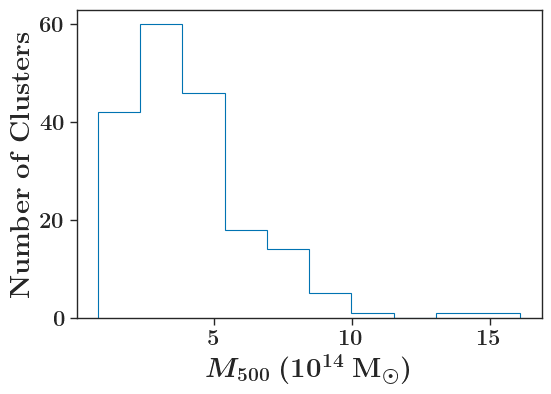

In [85]:
paper_plot()
fig = plt.figure()
plt.hist(reflex_clean['MSZ'], histtype='step')
plt.xlabel(f'$M_{{500}} ~ (10^{{14}} ~\mathrm{{M_{{\odot}}}})$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

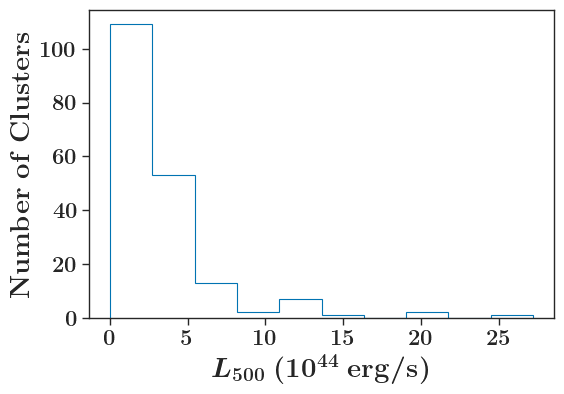

In [83]:


#plt.xlabel(f'$L500 (10^{{14}} Msun)$')
plt.hist(reflex_clean['L500'], histtype='step')
plt.xlabel(f'$L_{{500}}~ (10^{{44}} ~ \mathrm{{erg/s}})$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

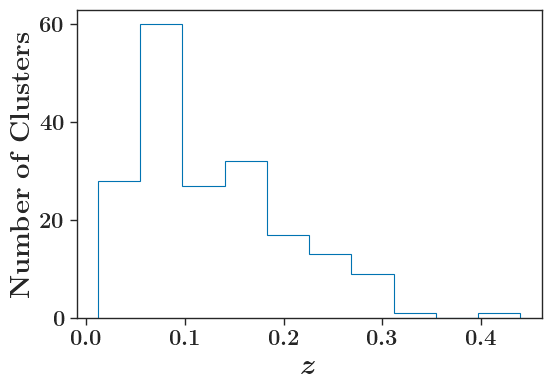

In [87]:
plt.hist(reflex_clean['z_y'], histtype='step')
plt.xlabel(f'$z$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

In [75]:
reflex_clean

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
543,J2347.7-2808,RXCJ2347.7-2808,A4038,23 47 43.2 -28 8 29,356.930 -28.141,25.139 -75.862,0.0300,NORAS/REFLEX,REFLEX,0.601,...,0.114748,0.107849,,,,-10,-1000.0,1,NaN,0.038488
546,J2351.6-2605,RXCJ2351.6-2605,A2667,23 51 40.7 -26 5 1,357.919 -26.084,34.017 -76.609,0.2264,NORAS/REFLEX,REFLEX,3.631,...,0.365168,0.382711,,,,-10,-1000.0,1,NaN,0.993468
547,J2354.2-1024,RXCJ2354.2-1024,A2670,23 54 13.4 -10 24 46,358.556 -10.413,81.334 -68.530,0.0765,NORAS/REFLEX,REFLEX,1.450,...,0.216913,0.225417,RMJ235413.7-102508.5,,,-10,-1000.0,1,NaN,0.151354
549,J2357.0-3445,RXCJ2357.0-3445,A4059,23 57 2.3 -34 45 38,359.260 -34.761,356.359 -76.082,0.0475,NORAS/REFLEX,REFLEX,0.931,...,0.163126,0.149009,,,,-10,-1000.0,1,NaN,0.091267


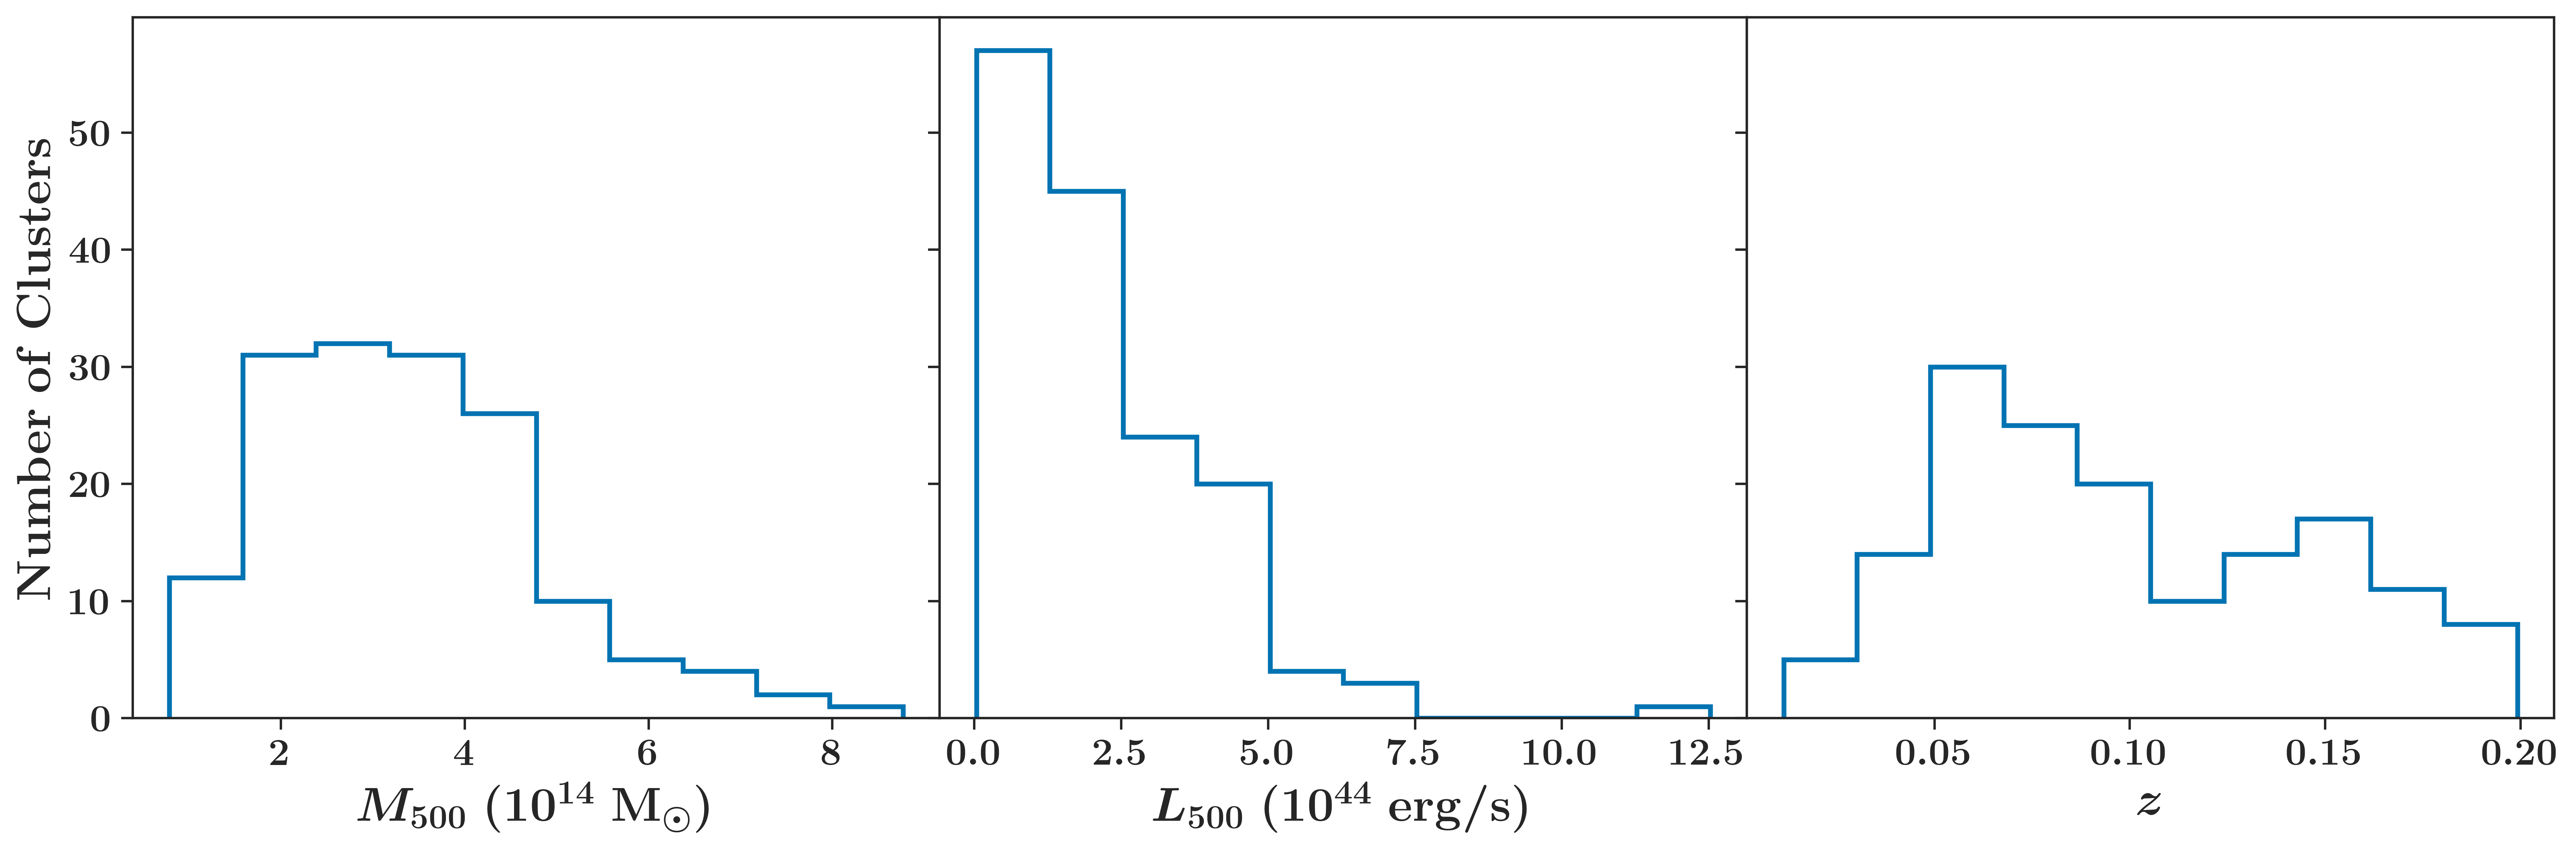

In [96]:
    lowz_data = reflex_clean[reflex_clean['z_y'] < 0.2]
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, gridspec_kw={'wspace': 0}, dpi=450)  # 1 row, 3 columns

    # First subplot
    axes[0].hist(lowz_data['MSZ'], histtype='step', lw=2)
    axes[0].set_xlabel(f'$M_{{500}} ~ (10^{{14}} ~\\mathrm{{M_{{\\odot}}}})$')
    axes[0].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')

    # Second subplot
    axes[1].hist(lowz_data['L500'], histtype='step', lw=2)
    axes[1].set_xlabel(f'$L_{{500}}~ (10^{{44}} ~ \\mathrm{{erg/s}})$')
    #axes[1].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')

    # Third subplot
    axes[2].hist(lowz_data['z_y'], histtype='step', lw=2)
    axes[2].set_xlabel(f'$z$')
    #axes[2].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')

    plt.tight_layout()  # Adjusts the layout so the labels and titles fit within the figure
    plt.show()
    fig.savefig('plots/REFLEX_clusters.pdf', bbox_inches='tight')

In [103]:
nfws_werr = generate_nfws_from_combined_dataset_werr(reflex_clean, variances)
# grab only low z clusters
nfws_subset = [nfw for nfw in nfws_werr if nfw.z < 0.2]
#L_obs = np.array([nfw.L500.to(u.erg/u.s).value for nfw in nfws_subset])
#variances_obs = np.array([nfw.L_err for nfw in nfws_subset])

In [105]:
(1e37*u.W).to(u.erg/u.s)

<Quantity 1.e+44 erg / s>

In [191]:
heating_rates = [nfw.total_heating_rate(0.001*nfw.R500, nfw.R500, 0.1*nfw.R500).value for nfw in nfws_subset]

In [192]:
heating_rates[0].value

4.169943111585336e+44

In [193]:
cooling_rates = [nfw.total_cooling_rate(0.001*nfw.R500, nfw.R500) for nfw in nfws_subset]

In [194]:
cooling_rates[0].value

8.188335573067685e+44

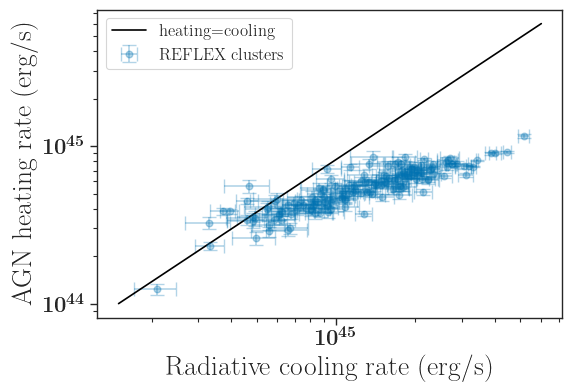

In [220]:
#plt.scatter(cooling_rates, heating_rates)
plt.errorbar(cooling_rates, [h for h in heating_rates],
             xerr=[[c.minus for c in cooling_rates],[c.plus for c in cooling_rates]],
             yerr=[[h.minus for h in heating_rates],[h.plus for h in heating_rates]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')


plt.plot([1.5e44, 6e45], [1e44, 6e45], label='heating=cooling', c='k')
plt.xscale('log')
plt.yscale('log')

#plt.xlim(2e44, 6e45)
#plt.ylim(2e44, 6e45)
plt.ylabel('AGN heating rate (erg/s)')
plt.xlabel('Radiative cooling rate (erg/s)')
plt.legend()

In [147]:
max(cooling_rates).value, min(cooling_rates).value

(5.359582240930958e+45, 2.401139372880963e+44)

In [150]:
data = pd.DataFrame({'cool': np.array([c.value for c in cooling_rates]),
                     'heat': np.array([h.value for h in heating_rates]), 
                     'c_err': np.array([max(c.minus, c.plus) for c in cooling_rates]),
                     'h_err': np.array([max(h.minus, h.plus) for h in heating_rates])})

In [188]:
number_of_bins = 10

bin_edges = np.linspace(data['cool'].min(), data['cool'].max(), number_of_bins + 1)

In [169]:
def sem(x):
    if len(x) == 0:
        return 0
    return 1./len(x) * np.sqrt(np.sum(x**2)) 

In [164]:
sem(data['c_err'])

4.947224239037621e+44

In [189]:
# Assign each data point to a bin in linear space
data['bin'] = pd.cut(data['cool'], bins=bin_edges, include_lowest=True)

# Aggregate data within bins
binned_data = data.groupby('bin').agg({
    'cool': 'mean',
    'heat': 'mean',
    'c_err': sem,
    'h_err': sem  # or use np.std / np.sqrt(len) for SEM
}).reset_index(drop=True)

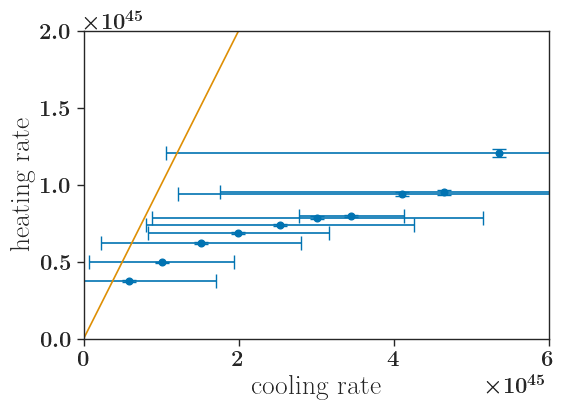

In [190]:
plt.errorbar(binned_data['cool'], binned_data['heat'], xerr=binned_data['c_err'], yerr=binned_data['h_err'], fmt='o', capsize=5)
plt.plot([0, 1e44, 1e46], [0, 1e44, 1e46], label='heating=cooling')
plt.xlabel('cooling rate')
plt.ylabel('heating rate')
#plt.title('Binned Data with Error Bars')
plt.xlim(0, 6e45)
plt.ylim(0, 2e45)
plt.show()
